--- Exploratory Data Analysis: Raw Data Summary ---
  Country name  Ladder score  Standard error of ladder score  upperwhisker  \
0      Finland         7.804                           0.036         7.875   
1      Denmark         7.586                           0.041         7.667   
2      Iceland         7.530                           0.049         7.625   
3       Israel         7.473                           0.032         7.535   
4  Netherlands         7.403                           0.029         7.460   

   lowerwhisker  Logged GDP per capita  Social support  \
0         7.733                 10.792           0.969   
1         7.506                 10.962           0.954   
2         7.434                 10.896           0.983   
3         7.411                 10.639           0.943   
4         7.346                 10.942           0.930   

   Healthy life expectancy  Freedom to make life choices  Generosity  \
0                   71.150                         0.961  

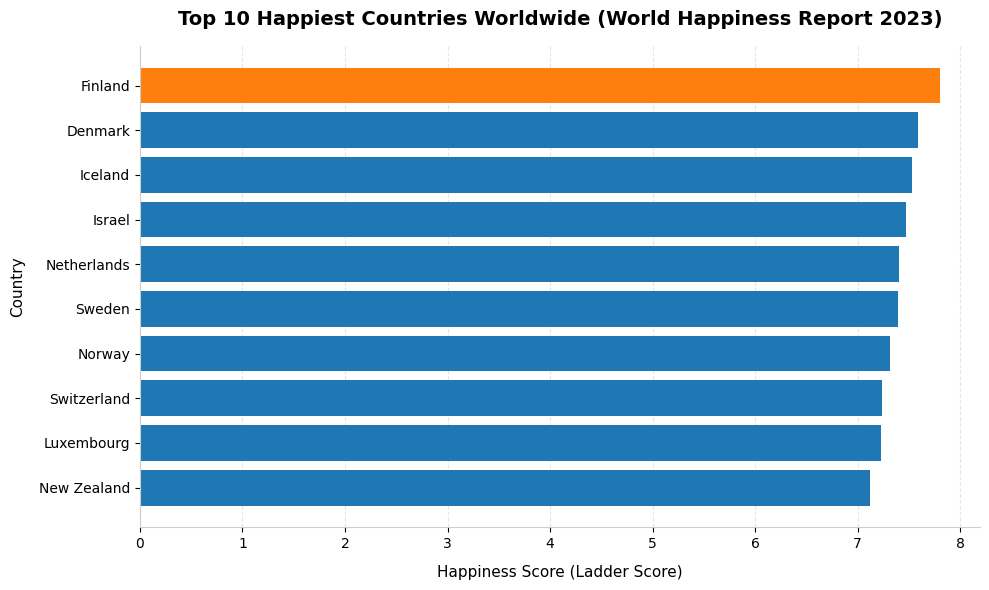

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================
# SECTION 1: LOAD & PREPARE DATA
# ==========================================
# Dataset source: World Happiness Report 2023 (Kaggle)
# Reference: Knaflic, C. N. (2015). Storytelling with data. Wiley.

# Load the dataset (Ensure 'WHR2023.csv' is in your working directory)
df = pd.read_csv("WHR2023.csv")

# Display basic exploratory info (Exploratory Analysis phase)
print("--- Exploratory Data Analysis: Raw Data Summary ---")
print(df.head())
print(df.info())

# Select top 10 happiest countries for our clean explanatory bar chart visualization
top_10 = df.nlargest(10, "Ladder score")  # 'Ladder score' represents happiness index

# ==========================================
# SECTION 2: EXPLORATORY VS. EXPLANATORY 
# ==========================================
# Following the concepts of "Context Before Charts" and moving from 
# raw data dumps (exploratory) to focused messaging (explanatory).
# Reference: [ FIGURE 0.2 — p.20 ] Ticket volume / raw data dump comparison.

fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

# Set custom colors to highlight the #1 country vs the rest (Clutter reduction)
colors = [
    "#1f77b4" if country != top_10.iloc[0]["Country name"] else "#ff7f0e"
    for country in top_10["Country name"]
]

# Create a clean horizontal bar chart for better readability of country names
bars = ax.barh(
    top_10["Country name"][::-1], top_10["Ladder score"][::-1], color=colors[::-1]
)

# ==========================================
# SECTION 3: FORMATTING & PROFESSIONAL POLISH
# ==========================================
# Removing chart clutter (spines) and adding clear annotations
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#cccccc")
ax.spines["bottom"].set_color("#cccccc")

# Titles and Labels styled for clear storytelling
plt.title(
    "Top 10 Happiest Countries Worldwide (World Happiness Report 2023)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Happiness Score (Ladder Score)", fontsize=11, labelpad=10)
plt.ylabel("Country", fontsize=11, labelpad=10)

# Gridlines for reference values only on the x-axis
ax.xaxis.grid(True, linestyle="--", alpha=0.5, color="#cccccc")
ax.set_axisbelow(True)

# Layout adjustments
plt.tight_layout()

# Save the explanatory output figure
plt.savefig("world_happiness_bar_chart.png", dpi=300)
print(
    "\n[SUCCESS] Chart generated successfully and saved as 'world_happiness_bar_chart.png'!"
)

# Show plot
plt.show()